In [1]:
#this cell starts off the notebook by loading all of the neeed tools, and also sets the location for the synthetic ISO code
import sys #python's "system" tool
from pathlib import Path #file-location tool
import numpy as np #libary for calculations, for radians --> degrees, and for calculations on whole lists at once
import pandas as pd #table library
import matplotlib.pyplot as plt #plotting library

sys.path.insert(0, str(Path.home() / "Synthetic-Population-of-Interstellar-Objects")) #path for synthetic ISo code
from synthetic_population import synthetic_population

In [4]:
%%time
seed_value = 1
np.random.seed(seed_value) #starting point for random numbers. Same seed gives same ISOs every time, so i can get consistent results. 1 is arbitrary.
q, e, f, inc, node, peri = synthetic_population(0, rm=5, n0=0.2, v_min=1e3, v_max=2e5,
                                                u_Sun=1e4, v_Sun=1.1e4, w_Sun=7e3,
                                                sigma_vx=3.1e4, sigma_vy=2.3e4, sigma_vz=1.6e4,
                                                vd=np.deg2rad(7), va=0, R_reff=696340000.,
                                                speed_resolution=500, angle_resolution=180, dr=0.01) #calls the function, it hands back six "lists", one for each orbital element
#the line above feeds the function a crap ton of different values to the function. This includes the sun's speed, how spread out the ISO's speeds are, the vertex deviation, asymmetric drift, the sun's radius in meters, how fine the program's outputs are (fine is more accurate but slower), and the number of ISOs (counting the es). This is sorted by lines the function is split into.
print(len(e), "synthetic ISOs made") #prints num of ISOs

5/5: Conversion to orbital elements: 100%|██████████| 133/133 [00:00<00:00, 6078.57it/s]

133 synthetic ISOs made
CPU times: user 1min 6s, sys: 42.9 s, total: 1min 49s
Wall time: 2min 14s


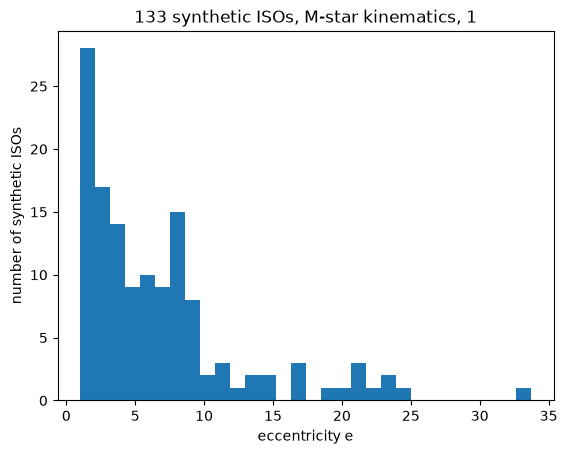

smallest e: 1.0038885682865353 | median e: 5.074673858035957 | largest e: 33.726197635775875


In [9]:
#this cell is a check that the fake ISO's "make sense". Every ISO must have an e value above 1, meaning its unbound. The histogram will also show how the e values are spread out, allowing me to compare to the real discovered ISOs
plt.hist(e, bins=30) #draws histogram of the e values. Splits the range of e into 30 equal "bins", and draws a bar for the amount of ISos that land in each
plt.xlabel("eccentricity e") #labels bottom axis
plt.ylabel("number of synthetic ISOs") #labels the side axis
plt.title(f"{len(e)} synthetic ISOs, M-star kinematics, {seed_value}") #sets title
plt.savefig("../figures/synthetic_e_hist_v1.png", dpi=150) #saves the picture
plt.show()
print("smallest e:", e.min(), "| median e:", np.median(e), "| largest e:", e.max())

In [10]:
#this cell will rearrange the formula to get each synthetic ISo's arrival speed. This checks that the M-star speeds went in correctly. IT then saves all 133 orbits to a file, since later steps also use that.
GM_SUN = 887.13 #the sun's gravity strength in au and km/s. capital letters mean it's a constant.
v_inf = np.sqrt((e-1) * GM_SUN / q) #calculates the speed
isos = pd.DataFrame({"q_au": q, "e": e, "v_inf_kms": v_inf, "inc_deg": np.rad2deg(inc), "node_deg": np.rad2deg(node), "peri_deg": np.rad2deg(peri), "f_deg": np.rad2deg(f)}) #builds a table named isos, one row per synthetic ISo, seven columns
isos.to_csv("../results/synthetic_isos_v1.csv", index=False) #saves the table in results folder
isos.describe().round(2) #shows summary for each column

,q_au,e,v_inf_kms,inc_deg,node_deg,peri_deg,f_deg
count,133.00,133.00,133.00,133.00,133.00,133.00,133.00
mean,2.78,6.73,38.22,93.98,179.45,194.27,-3.46
std,1.26,6.04,19.66,43.06,106.72,92.73,51.13
min,0.10,1.00,1.39,1.75,2.32,4.47,-147.14
25%,1.75,2.32,22.69,63.34,74.55,111.92,-39.75
50%,2.88,5.07,38.60,99.49,194.05,214.39,-6.19
75%,3.75,8.46,51.12,126.85,265.92,273.63,30.02
max,4.92,33.73,86.77,170.95,358.67,353.60,116.50
